# 03 – Estacionariedade, correlação cruzada e causalidade de Granger

**Entrada:** `data/processed/series_semanais_curitiba.csv` (recorte 2020–2022 = 155 semanas)  
**Saídas:**
- `results/figures/figura4_casos_vs_checagens_semanal.png`: **Figura 4** do TCC
- `results/figures/figura5_ccf_casos_checagens.png`: **Figura 5** do TCC
- `results/tables/tabela1_adf.csv`: **Tabela 1** do TCC
- `results/tables/tabela2_granger.csv`: **Tabela 2** do TCC
- `results/tables/ccf_valores.csv`: valores da CCF (lags 0 a 12)

O Granger é calculado com `grangercausalitytests` (regressões por defasagem, valor-p do teste F `ssr_ftest`). Não há estimação de um modelo VAR separado neste notebook.

As tentativas anteriores com ARIMA/ARIMAX/SARIMA/SARIMAX foram movidas para `archive/00_tentativa_arima_arimax.ipynb`.

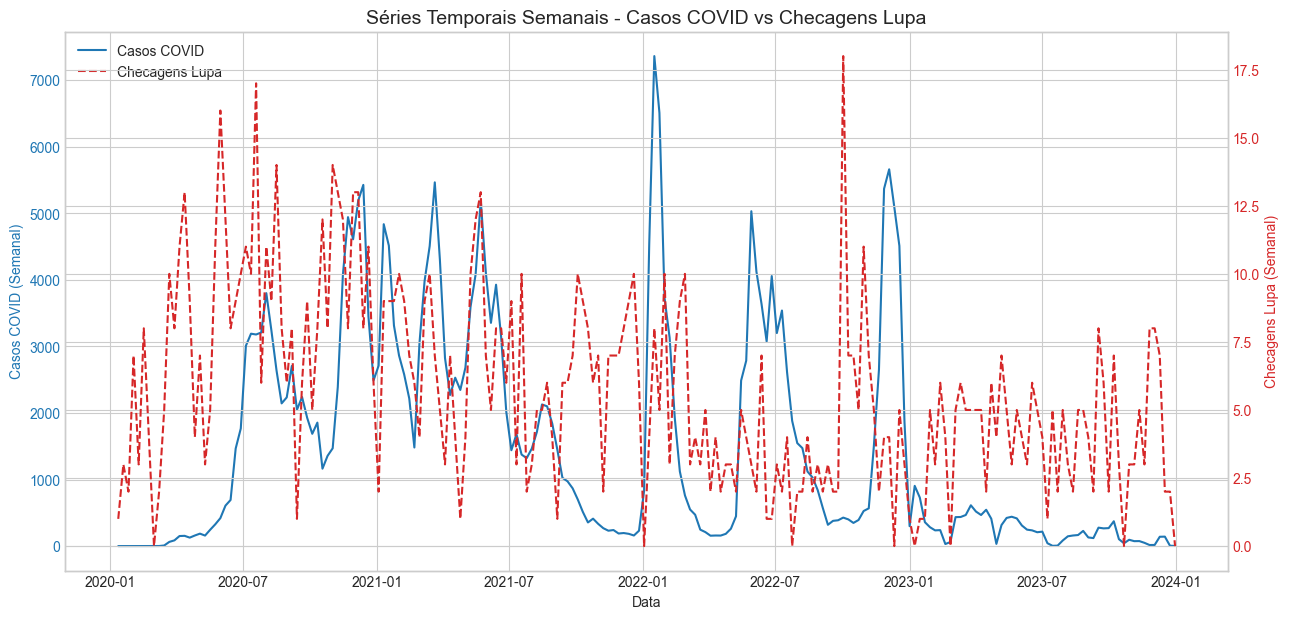

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

# Usar um estilo limpo
plt.style.use('seaborn-v0_8-whitegrid')

# 1. Carregar a base de dados unificada
caminho_dados = '../data/processed/series_semanais_curitiba.csv'
df_grafico = pd.read_csv(caminho_dados, index_col=0, parse_dates=True)

# Filtrar para garantir que o gráfico mostre apenas até o fim de 2023 (ou 2022)
df_grafico = df_grafico.loc['2020-01-01':'2023-12-31']

# 2. Criar a tela do gráfico no formato Widescreen
fig, ax1 = plt.subplots(figsize=(15, 7))

# 3. Eixo Esquerdo (Casos de COVID - Linha Azul Contínua)
cor_covid = 'tab:blue'
ax1.set_xlabel('Data')
ax1.set_ylabel('Casos COVID (Semanal)', color=cor_covid)
linha_covid = ax1.plot(df_grafico.index, df_grafico['casos_covid'], color=cor_covid, 
                       linestyle='-', label='Casos COVID')
ax1.tick_params(axis='y', labelcolor=cor_covid)

# 4. Eixo Direito (Checagens Lupa - Linha Vermelha Tracejada)
ax2 = ax1.twinx()  # Aqui está a mágica: criar um segundo eixo Y que compartilha o mesmo eixo X
cor_lupa = 'tab:red'
ax2.set_ylabel('Checagens Lupa (Semanal)', color=cor_lupa)
linha_lupa = ax2.plot(df_grafico.index, df_grafico['checagens_lupa'], color=cor_lupa, 
                      linestyle='--', label='Checagens Lupa')
ax2.tick_params(axis='y', labelcolor=cor_lupa)

# 5. Juntar as duas legendas no mesmo quadro no canto superior esquerdo
linhas = linha_covid + linha_lupa
labels = [l.get_label() for l in linhas]
ax1.legend(linhas, labels, loc='upper left')

# 6. Título do Gráfico, EXPORTAÇÃO E MOSTRAR GRÁFICO
plt.title('Séries Temporais Semanais - Casos COVID vs Checagens Lupa', fontsize=14)
plt.savefig('../results/figures/figura4_casos_vs_checagens_semanal.png', dpi=300, bbox_inches='tight')
plt.show()

In [2]:
# 1. Importar bibliotecas essenciais
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm # Para CCF e Granger
from statsmodels.tsa.stattools import adfuller # Teste de estacionariedade
import warnings
warnings.filterwarnings("ignore")

print("--- Iniciando Notebook 03: Correlação e Causalidade ---")

# Configurações de plotagem
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# 2. Carregar Dados Processados (Output do Notebook 02b)
path_processed = '../data/processed/series_semanais_curitiba.csv'
try:
    df = pd.read_csv(path_processed, index_col=0, parse_dates=True)
    df = df.asfreq('W-SUN') # Garantir frequência
    df.fillna(0, inplace=True) # Preencher possíveis NaNs

    print("Dados semanais carregados com sucesso:")
    print(df.head())

    # Separar as séries
    casos = df['casos_covid']
    desinfo = df['checagens_lupa']

except Exception as e:
    print(f"ERRO ao carregar dados processados: {e}")
    raise

--- Iniciando Notebook 03: Correlação e Causalidade ---
Dados semanais carregados com sucesso:
            casos_covid  checagens_lupa
2020-01-12            0               1
2020-01-19            0               3
2020-01-26            0               2
2020-02-02            0               7
2020-02-09            0               3


In [3]:
# 3. Definir Período de Análise e Verificar Estacionariedade
# Vamos usar o mesmo período de "treino" anterior (2020-2022)
inicio_analise = '2020-01-01'
fim_analise = '2022-12-31'

casos_analise = casos.loc[inicio_analise:fim_analise]
desinfo_analise = desinfo.loc[inicio_analise:fim_analise]

print(f"\nAnálise focada no período: {inicio_analise} a {fim_analise}")
print(f"Número de semanas na análise: {len(casos_analise)}")

# PASSO 1 Colocar em Estacionário
print("\n--- Verificando Estacionariedade (Teste ADF) ---")

def testar_estacionariedade(serie, nome):
    adf_result = adfuller(serie)
    print(f"\nTeste ADF para {nome}:")
    print(f'  ADF Statistic: {adf_result[0]:.4f}')
    print(f'  p-value: {adf_result[1]:.4f}')
    is_stationary = adf_result[1] < 0.05
    print(f"  Estacionária? {'Sim' if is_stationary else 'Não'}")
    return is_stationary

is_casos_stationary = testar_estacionariedade(casos_analise, "Casos COVID (Original)")
is_desinfo_stationary = testar_estacionariedade(desinfo_analise, "Checagens Lupa (Original)")

# Aplicar diferenciação (d=1) se não for estacionária
if not is_casos_stationary:
    casos_diff = casos_analise.diff().dropna()
    print("\nAplicando 1ª diferenciação em Casos COVID.")
    # Testar novamente após diferenciar
    testar_estacionariedade(casos_diff, "Casos COVID (1ª Dif)")
else:
    casos_diff = casos_analise

if not is_desinfo_stationary:
    desinfo_diff = desinfo_analise.diff().dropna()
    print("Aplicando 1ª diferenciação em Checagens Lupa.")
    # Testar novamente após diferenciar
    testar_estacionariedade(desinfo_diff, "Checagens Lupa (1ª Dif)")
else:
    desinfo_diff = desinfo_analise

# Alinhar os índices após a diferenciação (se feita)
common_index = casos_diff.index.intersection(desinfo_diff.index)
casos_final = casos_diff.loc[common_index]
desinfo_final = desinfo_diff.loc[common_index]

print(f"\nTamanho final das séries alinhadas para análise: {len(common_index)}")


Análise focada no período: 2020-01-01 a 2022-12-31
Número de semanas na análise: 155

--- Verificando Estacionariedade (Teste ADF) ---

Teste ADF para Casos COVID (Original):
  ADF Statistic: -4.7192
  p-value: 0.0001
  Estacionária? Sim

Teste ADF para Checagens Lupa (Original):
  ADF Statistic: -5.2757
  p-value: 0.0000
  Estacionária? Sim

Tamanho final das séries alinhadas para análise: 155



--- Calculando Correlação Cruzada (CCF) ---


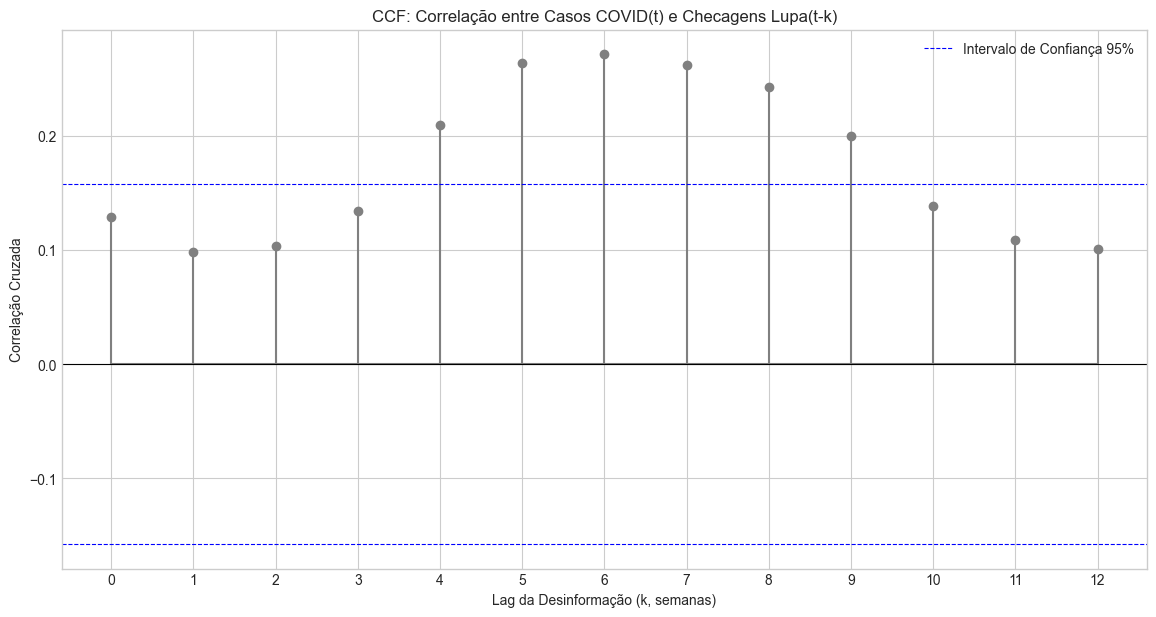


Interpretação CCF:
 - Picos significativos (bolinhas fora do intervalo azul) em lags k > 0 sugerem que a desinformação k semanas ANTES está correlacionada com os casos atuais.


In [4]:
# Investigar a Defasagem (Lag) com o CCF
print("\n--- Calculando Correlação Cruzada (CCF) ---")

# nlags: número máximo de lags para calcular (positivos e negativos)
max_lags_ccf = 12 # Testar até 12 semanas de defasagem
# Nota: sm.tsa.stattools.ccf(x, y) calcula Corr(x[t], y[t-k])
ccf_values = sm.tsa.stattools.ccf(casos_final, desinfo_final, adjusted=False) 

lags_plot = np.arange(0, max_lags_ccf + 1)
ccf_plot = ccf_values[:max_lags_ccf+1] # Pegar só os lags k >= 0 (onde desinfo está no passado)

# Calcular intervalo de confiança aproximado (para ruído branco)
conf_interval = 1.96 / np.sqrt(len(casos_final))

# Plotar CCF
plt.figure(figsize=(14, 7))
plt.stem(lags_plot, ccf_plot, linefmt='grey', markerfmt='o', basefmt='grey')
plt.axhline(0, color='black', linewidth=0.8)
plt.axhline(conf_interval, color='blue', linestyle='--', linewidth=0.8, label='Intervalo de Confiança 95%')
plt.axhline(-conf_interval, color='blue', linestyle='--', linewidth=0.8)
plt.xlabel("Lag da Desinformação (k, semanas)")
plt.ylabel("Correlação Cruzada")
plt.title(f"CCF: Correlação entre Casos COVID(t) e Checagens Lupa(t-k)")
plt.xticks(np.arange(0, max_lags_ccf + 1, 1)) # Mostrar todos os lags no eixo x
plt.legend()
plt.grid(True)
plt.savefig('../results/figures/figura5_ccf_casos_checagens.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nInterpretação CCF:")
print(" - Picos significativos (bolinhas fora do intervalo azul) em lags k > 0 sugerem que a desinformação k semanas ANTES está correlacionada com os casos atuais.")

In [5]:
# Causalidade de Granger
print("\n--- Testando Causalidade de Granger ---")
print("Verifica se os lags da Desinformação ajudam a prever Casos COVID.")

# O teste requer um DataFrame com as duas séries (potencialmente diferenciadas)
df_granger = pd.DataFrame({'casos': casos_final, 'desinfo': desinfo_final})

max_lag_granger = 8 # Testar causalidade com até 8 lags (pode ajustar)

# Hipótese Nula (H0): Lags de 'desinfo' NÃO Granger-causam 'casos'.
# Se p-valor < 0.05 em algum teste, rejeitamos H0.

try:
    # Testar Desinformação -> Casos
    print("\n--- Teste: Desinformação (X) -> Casos COVID (Y) ---")
    gc_res_x_to_y = sm.tsa.stattools.grangercausalitytests(df_granger[['casos', 'desinfo']], # Ordem importa: Y (alvo) vem primeiro
                                                           maxlag=max_lag_granger,
                                                           verbose=True) # verbose=True imprime os resultados

    print("\nInterpretação Granger (X -> Y):")
    print(" - Para cada lag testado, olhe o p-valor (última coluna da tabela F-test).")
    print(" - Se p < 0.05, indica que os lags da Desinformação SÃO úteis para prever Casos COVID.")
    
    print("\n" + "="*40 + "\n")

    # Testar Casos -> Desinformação (a via oposta)
    print("\n--- Teste: Casos COVID (Y) -> Desinformação (X) ---")
    gc_res_y_to_x = sm.tsa.stattools.grangercausalitytests(df_granger[['desinfo', 'casos']], # Ordem invertida
                                                           maxlag=max_lag_granger,
                                                           verbose=True)
    
    print("\nInterpretação Granger (Y -> X):")
    print(" - Se p < 0.05 aqui, indica que os picos de Casos COVID podem ter gerado mais checagens da Lupa (reação).")


except Exception as e:
    print(f"\nERRO ao executar o teste de Granger: {e}")
    print("Isso pode ocorrer se as séries não forem adequadamente estacionárias ou tiverem problemas.")

# 5. Conclusões Preliminares
print("\n--- Fim da Análise de Correlação e Causalidade ---")
# Aqui você escreverá suas conclusões com base nos resultados da CCF e Granger.


--- Testando Causalidade de Granger ---
Verifica se os lags da Desinformação ajudam a prever Casos COVID.

--- Teste: Desinformação (X) -> Casos COVID (Y) ---

Granger Causality
number of lags (no zero) 1
ssr based F test:         F=0.1660  , p=0.6843  , df_denom=151, df_num=1
ssr based chi2 test:   chi2=0.1693  , p=0.6808  , df=1
likelihood ratio test: chi2=0.1692  , p=0.6809  , df=1
parameter F test:         F=0.1660  , p=0.6843  , df_denom=151, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=1.2232  , p=0.2973  , df_denom=148, df_num=2
ssr based chi2 test:   chi2=2.5290  , p=0.2824  , df=2
likelihood ratio test: chi2=2.5083  , p=0.2853  , df=2
parameter F test:         F=1.2232  , p=0.2973  , df_denom=148, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=1.4875  , p=0.2204  , df_denom=145, df_num=3
ssr based chi2 test:   chi2=4.6779  , p=0.1970  , df=3
likelihood ratio test: chi2=4.6073  , p=0.2029  , df=3
paramet

## Exportação das Tabelas 1 e 2 e dos valores da CCF

Apenas organiza em CSV os resultados já calculados acima.

In [6]:
import os
os.makedirs('../results/tables', exist_ok=True)

# TABELA 1 – ADF
tab1 = []
for nome, serie in [('Casos COVID-19', casos_analise), ('Checagens Agência Lupa', desinfo_analise)]:
    r = adfuller(serie)
    tab1.append({'variavel': nome, 'estatistica_adf': round(r[0], 4), 'valor_p': round(r[1], 4),
                 'estacionaria_5pct': 'Sim (Nível)' if r[1] < 0.05 else 'Não'})
tab1 = pd.DataFrame(tab1)
tab1.to_csv('../results/tables/tabela1_adf.csv', index=False)
print(tab1.to_string(index=False))

# TABELA 2 – Granger bidirecional (valor-p do teste F, ssr_ftest)
tab2 = pd.DataFrame({
    'lag': list(range(1, max_lag_granger + 1)),
    'desinformacao_para_covid_p': [round(gc_res_x_to_y[l][0]['ssr_ftest'][1], 4) for l in range(1, max_lag_granger + 1)],
    'covid_para_desinformacao_p': [round(gc_res_y_to_x[l][0]['ssr_ftest'][1], 4) for l in range(1, max_lag_granger + 1)],
})
tab2.to_csv('../results/tables/tabela2_granger.csv', index=False)
print()
print(tab2.to_string(index=False))

# Valores da CCF exibidos na Figura 5
pd.DataFrame({'lag': lags_plot, 'ccf': ccf_plot.round(4), 'limite_ic95': round(conf_interval, 4)})\
  .to_csv('../results/tables/ccf_valores.csv', index=False)

              variavel  estatistica_adf  valor_p estacionaria_5pct
        Casos COVID-19          -4.7192   0.0001       Sim (Nível)
Checagens Agência Lupa          -5.2757   0.0000       Sim (Nível)

 lag  desinformacao_para_covid_p  covid_para_desinformacao_p
   1                      0.6843                      0.6169
   2                      0.2973                      0.3030
   3                      0.2204                      0.4518
   4                      0.0647                      0.6543
   5                      0.0961                      0.7814
   6                      0.1216                      0.7894
   7                      0.1925                      0.8154
   8                      0.2803                      0.7777
